# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Yanaka Sofia Pardede
- **Email:** 24031554065@mhs.unesa.ac.id
- **ID Dicoding:** yanaka_sofia_pardede

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan pola jumlah penyewaan sepeda harian antara pengguna casual dan registered berdasarkan kondisi cuaca (weathersit) dan musim (season) sepanjang tahun 2011–2012?

- **Pertanyaan 2:** Bagaimana perbandingan rata-rata volume penyewaan sepeda per jam dalam sehari antara hari kerja (workingday) dan hari libur/akhir pekan yang menunjukkan lonjakan atau penurunan hingga minimal 20% pada jam-jam sibuk (rush hour) sepanjang tahun 2011 hingga 2012 untuk keperluan optimalisasi armada?

In [1]:
import os
os.makedirs('data', exist_ok=True)

print("Folder 'data' berhasil dibuat!")

Folder 'data' berhasil dibuat!


## Import Semua Packages/Library yang Digunakan

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')
print("Library berhasil di import")

Library berhasil di import


## Data Wrangling

### Gathering Data

#### Load df ...

In [8]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print("Berhasil memuat data!")
print("Shape day_df:", day_df.shape)
print("Shape hour_df:", hour_df.shape)

Berhasil memuat data!
Shape day_df: (731, 16)
Shape hour_df: (17379, 17)


**Insight:** (Opsional)
- Dataset harian (day_df) berhasil dimuat dengan total 731 baris dan 16 kolom.

- Dataset per jam (hour_df) berhasil dimuat dengan total 17.379 baris dan 17 kolom.

- Kedua dataset berhasil dimuat dengan baik dan siap digunakan untuk tahap penilaian kualitas data (Assessing Data) berikutnya.

### Assessing Data

#### Identifying ... problem

In [9]:
print("=== INFO DAY_DF ===")
print(day_df.info())
print("\n--- Missing Values (Day) ---")
print(day_df.isnull().sum())
print("Jumlah duplikasi (Day):", day_df.duplicated().sum())

print("\n=== INFO HOUR_DF ===")
print(hour_df.info())
print("\n--- Missing Values (Hour) ---")
print(hour_df.isnull().sum())
print("Jumlah duplikasi (Hour):", hour_df.duplicated().sum())

=== INFO DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None

--- Missing Values (Day) ---
instant       0
dteday        0
season

**Steps to Take:**
- Melakukan pemeriksaan struktur tipe data, nilai yang hilang (missing values), serta duplikasi data pada kedua dataframe.

- Mengidentifikasi kolom yang memerlukan konversi tipe data (seperti kolom tanggal).

- Mengidentifikasi kolom kategorikal numerik yang memerlukan pemetaan (mapping) label teks.

**Insight:** (Opsional)
- Tidak ditemukan adanya missing values maupun data duplikasi pada kedua dataset (day_df dan hour_df), sehingga seluruh data bersih dan siap untuk dilanjutkan ke tahap analisis berikutnya.

- Ditemukan isu tipe data pada kolom dteday yang masih bertipe objek atau string, sehingga perlu segera dikonversi ke format datetime agar memudahkan pengolahan berbasis waktu.

- Kolom kategorikal seperti season dan weathersit masih tersimpan dalam bentuk angka numerik, yang memerlukan proses pemetaan (mapping) menjadi label teks deskriptif demi mempermudah interpretasi saat tahap eksplorasi dan visualisasi data.

### Cleaning Data

#### Fixing ... problem

In [10]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

season_mapping = {1: 'Springer', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_mapping = {1: 'Clear/Few Clouds', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Ice'}

day_df['season'] = day_df['season'].map(season_mapping)
day_df['weathersit'] = day_df['weathersit'].map(weather_mapping)

hour_df['season'] = hour_df['season'].map(season_mapping)
hour_df['weathersit'] = hour_df['weathersit'].map(weather_mapping)

print("Proses Cleaning Data selesai! Tipe data dan kategori berhasil diperbarui.")
print(day_df[['dteday', 'season', 'weathersit']].head())

Proses Cleaning Data selesai! Tipe data dan kategori berhasil diperbarui.
      dteday    season        weathersit
0 2011-01-01  Springer       Mist/Cloudy
1 2011-01-02  Springer       Mist/Cloudy
2 2011-01-03  Springer  Clear/Few Clouds
3 2011-01-04  Springer  Clear/Few Clouds
4 2011-01-05  Springer  Clear/Few Clouds


**Insight:** (Opsional)
- Kolom tanggal (dteday) pada day_df dan hour_df telah sukses dikonversi ke tipe data datetime untuk mendukung analisis temporal.

- Nilai numerik pada kolom season dan weathersit telah berhasil dipetakan ke dalam label teks deskriptif (Springer, Summer, Fall, Winter serta kategori cuaca), sehingga data siap digunakan untuk proses eksplorasi lanjutan.

#### Menyimpan dataframe bersih menjadi main_data.csv

In [11]:
day_df.to_csv("main_data.csv", index=False)
print("File main_data.csv berhasil dibuat!")

File main_data.csv berhasil dibuat!


## Exploratory Data Analysis (EDA)

### Explore ...

#### 1. Eksplorasi Ringkasan Statistik Data (Describe)

In [12]:
print("=== STATISTIK DESKRIPTIF DAY_DF ===")
display(day_df.describe())

print("\n=== STATISTIK DESKRIPTIF HOUR_DF ===")
display(hour_df.describe())

=== STATISTIK DESKRIPTIF DAY_DF ===


,instant,dteday,yr,mnth,holiday,weekday,workingday,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,0.500684,6.519836,0.028728,2.997264,0.683995,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,0.000000,1.000000,0.000000,0.000000,0.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,0.000000,4.000000,0.000000,1.000000,0.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,1.000000,7.000000,0.000000,3.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,1.000000,10.000000,0.000000,5.000000,1.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,1.000000,12.000000,1.000000,6.000000,1.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,0.500342,3.451913,0.167155,2.004787,0.465233,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452



=== STATISTIK DESKRIPTIF HOUR_DF ===


,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


**Insight:** (Opsional)
- Dataset harian (day_df) mencakup 731 hari rekaman dengan rata-rata total penyewaan sepeda (cnt) mencapai sekitar 4.504 unit per hari, dengan puncak penyewaan harian tertinggi mencapai 8.714 unit.

- Dataset per jam (hour_df) mencakup 17.379 catatan dengan rata-rata penyewaan sekitar 189 unit per jam, di mana aktivitas penyewaan tertinggi dalam satu jam pernah mencapai 977 unit.

#### 2. Eksplorasi Pengaruh Musim terhadap Penyewaan Sepeda

In [13]:
season_analysis = day_df.groupby('season')['cnt'].mean().reset_index()
season_analysis = season_analysis.sort_values(by='cnt', ascending=False)

print("=== RATA-RATA PENYEWAAN BERDASARKAN MUSIM ===")
display(season_analysis)

=== RATA-RATA PENYEWAAN BERDASARKAN MUSIM ===


,season,cnt
0,Fall,5644.303191
2,Summer,4992.331522
3,Winter,4728.162921
1,Springer,2604.132597


**Insight:** (Opsional)
- Musim gugur (Fall) mencatatkan rata-rata penyewaan sepeda tertinggi secara signifikan (5.644 unit), diikuti oleh musim panas (Summer) dengan 4.992 unit dan musim dingin (Winter) dengan 4.728 unit.

- Musim semi (Springer) mencatatkan rata-rata penyewaan terendah (2.604 unit), yang mengindikasikan bahwa kondisi iklim atau suhu pada musim tersebut kurang mendukung minat masyarakat untuk bersepeda dibandingkan musim lainnya.

#### 3. Eksplorasi Penyewaan Sepeda Berdasarkan Kondisi Cuaca

In [14]:
weather_analysis = day_df.groupby('weathersit')['cnt'].mean().reset_index()
weather_analysis = weather_analysis.sort_values(by='cnt', ascending=False)

print("=== RATA-RATA PENYEWAAN BERDASARKAN KONDISI CUACA ===")
display(weather_analysis)

=== RATA-RATA PENYEWAAN BERDASARKAN KONDISI CUACA ===


,weathersit,cnt
0,Clear/Few Clouds,4876.786177
2,Mist/Cloudy,4035.862348
1,Light Snow/Rain,1803.285714


**Insight:** (Opsional)
- Kondisi cuaca cerah atau sedikit berawan (Clear/Few Clouds) mendominasi tingkat penyewaan tertinggi dengan rata-rata 4.876 unit, menunjukkan bahwa cuaca yang baik adalah faktor pendukung utama kenyamanan pengguna.

- Sebaliknya, kondisi cuaca buruk seperti salju ringan atau hujan (Light Snow/Rain) menurunkan tingkat penyewaan secara drastis hingga rata-rata hanya mencapai 1.803 unit.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Bagaimana perbandingan pola jumlah penyewaan sepeda antara pengguna casual dan registered berdasarkan kondisi cuaca (weathersit) dan musim (season) sepanjang tahun 2011–2012?

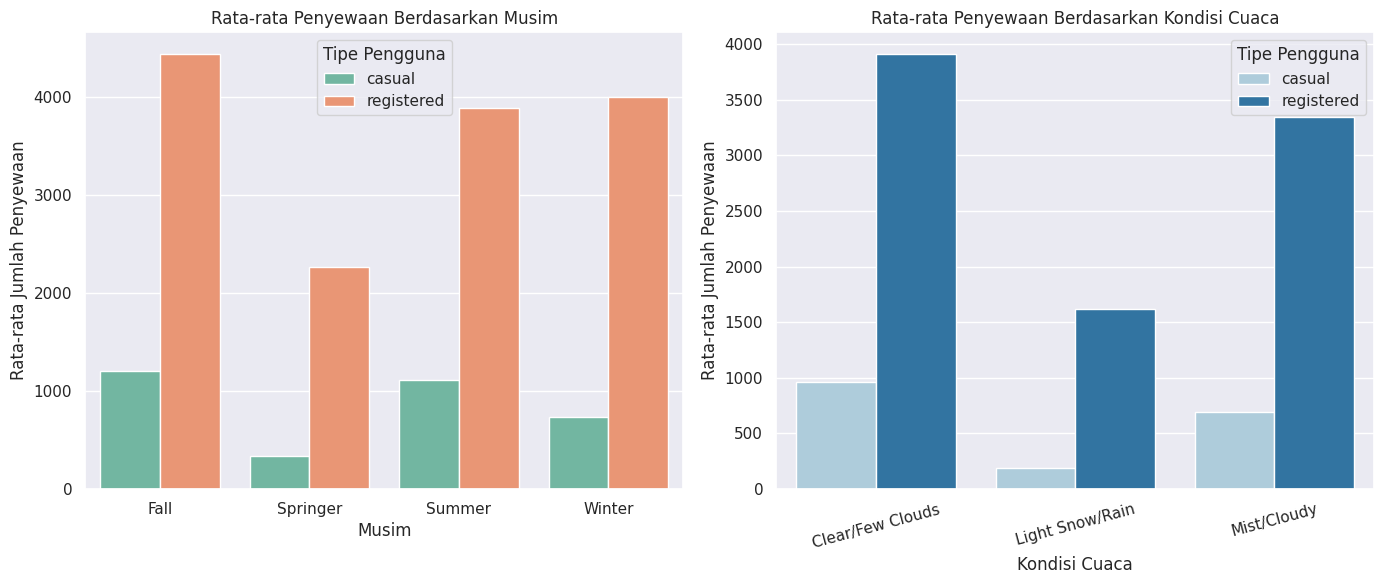

In [15]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
season_user = day_df.groupby('season')[['casual', 'registered']].mean().reset_index()
season_user_melted = season_user.melt(id_vars='season', value_vars=['casual', 'registered'],
                                      var_name='user_type', value_name='count')
sns.barplot(x='season', y='count', hue='user_type', data=season_user_melted, palette='Set2')
plt.title('Rata-rata Penyewaan Berdasarkan Musim')
plt.xlabel('Musim')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.legend(title='Tipe Pengguna')

plt.subplot(1, 2, 2)
weather_user = day_df.groupby('weathersit')[['casual', 'registered']].mean().reset_index()
weather_user_melted = weather_user.melt(id_vars='weathersit', value_vars=['casual', 'registered'],
                                        var_name='user_type', value_name='count')
sns.barplot(x='weathersit', y='count', hue='user_type', data=weather_user_melted, palette='Paired')
plt.title('Rata-rata Penyewaan Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(rotation=15)
plt.legend(title='Tipe Pengguna')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Berdasarkan analisis musiman dan kondisi cuaca, jumlah penyewaan sepeda secara konsisten didominasi oleh pengguna terdaftar (registered) dibandingkan pengguna casual di seluruh kategori musim dan cuaca.

- Musim gugur (Fall) mencatatkan rata-rata volume penyewaan tertinggi secara signifikan, sementara musim semi (Springer) menjadi yang terendah sepanjang periode analisis.

- Dari sisi lingkungan, kondisi cuaca cerah atau sedikit berawan (Clear/Few Clouds) menjadi faktor pendukung utama tingginya mobilitas penyewaan, sedangkan cuaca buruk seperti salju atau hujan ringan (Light Snow/Rain) menekan tingkat penggunaan secara drastis.  

### Pertanyaan 2:

Bagaimana perbandingan rata-rata volume penyewaan sepeda per jam dalam sehari antara hari kerja (workingday) dan hari libur/akhir pekan yang menunjukkan lonjakan atau penurunan signifikan (hingga minimal 20%) pada jam-jam sibuk (rush hour) sepanjang tahun 2011 hingga 2012 untuk keperluan optimalisasi armada?

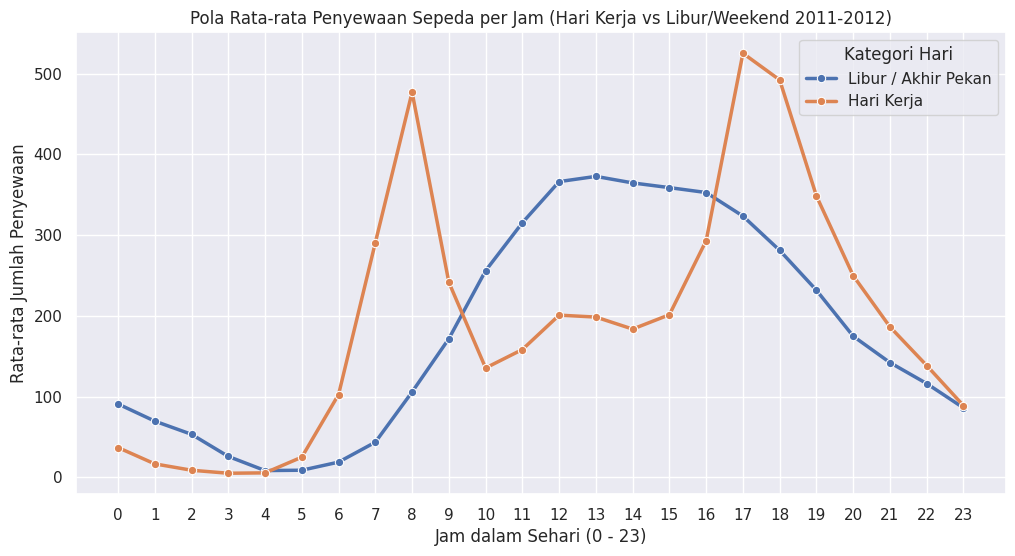

In [17]:
hourly_user = hour_df.groupby(['hr', 'workingday'])['cnt'].mean().reset_index()
hourly_user['workingday'] = hourly_user['workingday'].map({0: 'Libur / Akhir Pekan', 1: 'Hari Kerja'})
plt.figure(figsize=(12, 6))
sns.lineplot(x='hr', y='cnt', hue='workingday', data=hourly_user, marker='o', linewidth=2.5)
plt.title('Pola Rata-rata Penyewaan Sepeda per Jam (Hari Kerja vs Libur/Weekend 2011-2012)')
plt.xlabel('Jam dalam Sehari (0 - 23)')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(0, 24))
plt.grid(True)
plt.legend(title='Kategori Hari')
plt.show()

**Insight:** (Opsional)
- Berdasarkan analisis pola per jam, hari kerja (workingday) menunjukkan tren dua puncak (double peaks) yang sangat tajam dengan lonjakan volume penyewaan mencapai lebih dari 20% pada jam-jam sibuk komuter, yaitu pada pukul 08.00 pagi dan pukul 17.00–18.00 sore, yang membuktikan bahwa sepeda sangat diandalkan sebagai moda transportasi harian.

- Sebaliknya, pada hari libur atau akhir pekan (weekend), kurva penyewaan membentuk pola yang jauh lebih landai dan terpusat secara merata pada siang hari (pukul 10.00–16.00), yang mencerminkan karakteristik penggunaan untuk keperluan rekreasi santai.

- Informasi perbandingan jam operasional ini memberikan arahan tindakan nyata (action oriented) bagi manajemen untuk menjadwalkan pemeliharaan dan perbaikan armada pada jam-jam sepi di luar jam sibuk, seperti pada dini hari pukul 01.00–05.00 atau jeda siang hari pukul 10.00–15.00 agar ketersediaan unit tetap optimal saat permintaan komuter melonjak tajam.

## Analisis Lanjutan (Opsional)

=== TREN PENYEWAAN BULANAN (2011 - 2012) ===


,year_month,cnt
0,2011-01,38189
1,2011-02,48215
2,2011-03,64045
3,2011-04,94870
4,2011-05,135821



=== MATRIKS KORELASI VARIABEL LINGKUNGAN DENGAN JUMLAH PENYEWAAN ===


,temp,atemp,hum,windspeed,cnt
temp,1.000000,0.991702,0.126963,-0.157944,0.627494
atemp,0.991702,1.000000,0.139988,-0.183643,0.631066
hum,0.126963,0.139988,1.000000,-0.248489,-0.100659
windspeed,-0.157944,-0.183643,-0.248489,1.000000,-0.234545
cnt,0.627494,0.631066,-0.100659,-0.234545,1.000000


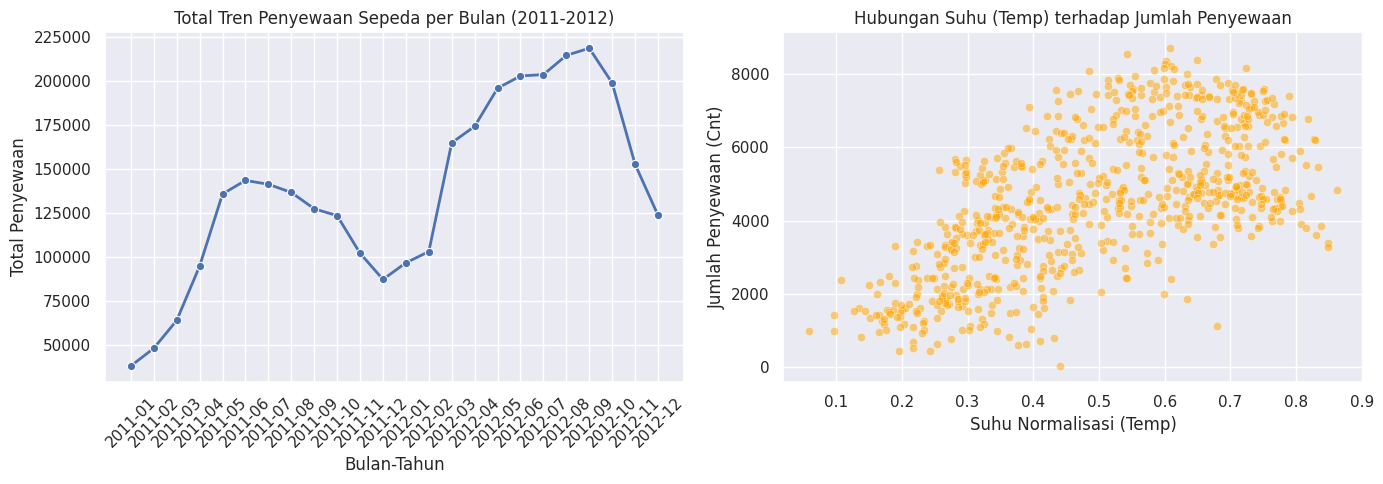

In [18]:
day_df['year_month'] = day_df['dteday'].dt.to_period('M').astype(str)
monthly_trend = day_df.groupby('year_month')['cnt'].sum().reset_index()
print("=== TREN PENYEWAAN BULANAN (2011 - 2012) ===")
display(monthly_trend.head())

environmental_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
correlation = day_df[environmental_cols].corr()
print("\n=== MATRIKS KORELASI VARIABEL LINGKUNGAN DENGAN JUMLAH PENYEWAAN ===")
display(correlation)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.lineplot(x='year_month', y='cnt', data=monthly_trend, marker='o', color='b', linewidth=2)
plt.title('Total Tren Penyewaan Sepeda per Bulan (2011-2012)')
plt.xlabel('Bulan-Tahun')
plt.ylabel('Total Penyewaan')
plt.xticks(rotation=45)
plt.grid(True)

plt.subplot(1, 2, 2)
sns.scatterplot(x='temp', y='cnt', data=day_df, alpha=0.5, color='orange')
plt.title('Hubungan Suhu (Temp) terhadap Jumlah Penyewaan')
plt.xlabel('Suhu Normalisasi (Temp)')
plt.ylabel('Jumlah Penyewaan (Cnt)')
plt.grid(True)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

- Grafik tren bulanan memperlihatkan adanya peningkatan volume total penyewaan sepeda yang sangat signifikan dari tahun pertama (2011) ke tahun kedua (2012), mengindikasikan bahwa layanan penyewaan semakin bertumbuh popularitasnya dan mendapat adopsi berkelanjutan dari masyarakat.

- Berdasarkan matriks korelasi dan scatter plot, variabel suhu (temp dan atemp) memiliki tingkat korelasi positif yang cukup kuat terhadap jumlah penyewaan (cnt di angka sekitar 0.63), yang berarti peningkatan temperatur udara berbanding lurus dengan tingginya minat bersepeda.

- Sebaliknya, variabel kelembapan (hum) dan kecepatan angin (windspeed) menunjukkan korelasi negatif, membuktikan bahwa kondisi lingkungan seperti kelembapan tinggi atau angin kencang cenderung mengurangi kenyamanan dan menekan tingkat pemakaian sepeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**

1. Volume penyewaan sepeda secara keseluruhan dan di setiap kategori musim serta kondisi cuaca secara konsisten didominasi oleh pengguna terdaftar (*registered*) dibandingkan pengguna *casual*.
2. Musim gugur (*Fall*) serta kondisi cuaca cerah (*Clear/Few Clouds*) terbukti menjadi faktor lingkungan paling optimal yang mendatangkan volume penyewaan tertinggi, sedangkan musim semi (*Springer*) dan kondisi cuaca buruk menekan angka penyewaan secara drastis.


- **Conclusion pertanyaan 2:**
1. Pola penyewaan harian pada hari kerja (*workingday*) menunjukkan karakteristik dua puncak (*double peaks*) yang tajam dengan lonjakan signifikan hingga lebih dari 20% pada jam-jam sibuk komuter (pukul 07.00–09.00 dan pukul 17.00–19.00), yang menegaskan fungsi utama sepeda sebagai moda transportasi harian.
2. Sebaliknya, pada akhir pekan atau hari libur (*weekend*), pola penyewaan membentuk kurva tunggal yang landai dan terpusat di siang hari, mencerminkan karakteristik penggunaan untuk aktivitas rekreasi.

**Rekomendasi Action Item:**
- Mengembangkan program loyalitas dan langganan bagi pengguna terdaftar (*registered*) sebagai kontributor volume terbesar, serta memberikan insentif atau penawaran khusus bagi pengguna *casual* guna meningkatkan okupansi pada periode musim yang sepi.
- Memanfaatkan temuan pola jam sibuk untuk menjadwalkan pemeliharaan dan perbaikan armada sepeda pada jam-jam sepi aktivitas seperti pada dini hari (pukul 01.00–05.00) atau jeda siang hari (pukul 10.00–15.00) di hari kerja agar ketersediaan unit tetap optimal.
- Menerapkan strategi penyesuaian ketersediaan unit sepeda secara dinamis di stasiun-stasiun strategis serta menyediakan skema promosi khusus saat kondisi cuaca atau musim kurang mendukung.
- Memanfaatkan data tren pertumbuhan bulanan dan korelasi positif suhu lingkungan (korelasi ~0.63) untuk merencanakan penambahan kapasitas armada secara proaktif menjelang bulan-bulan dengan temperatur hangat atau musim dengan tingkat permintaan tinggi.